In [1]:
from fontTools.misc.arrayTools import scaleRect
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv("income.csv")
df.head()

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


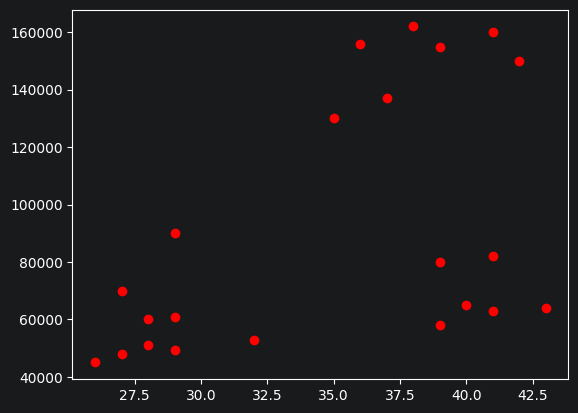

In [3]:
plt.scatter(df.Age, df["Income($)"], marker='o', color='red')

In [4]:
km = KMeans(n_clusters=3)
km

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [5]:
y_predicted = km.fit_predict(df[["Age", "Income($)"]])

In [6]:
df["cluster"] = y_predicted

In [7]:
df.head()

,Name,Age,Income($),cluster
0,Rob,27,70000,2
1,Michael,29,90000,0
2,Mohan,29,61000,2
3,Ismail,28,60000,2
4,Kory,42,150000,1


In [8]:
df0 = df[df.cluster == 0]
df1 = df[df.cluster == 1]
df2 = df[df.cluster == 2]

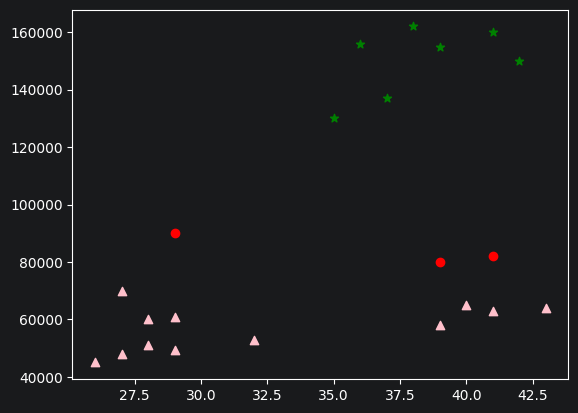

In [9]:
plt.scatter(df0["Age"], df0["Income($)"], marker='o', color='red')
plt.scatter(df1["Age"], df1["Income($)"], marker='*', color='green')
plt.scatter(df2["Age"], df2["Income($)"], marker='^', color='pink')

In [10]:
scaler = MinMaxScaler()
df["Income($)"] = scaler.fit_transform(df[["Income($)"]])
df["Age"] = scaler.fit_transform(df[["Age"]])
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,2
1,Michael,0.176471,0.384615,0
2,Mohan,0.176471,0.136752,2
3,Ismail,0.117647,0.128205,2
4,Kory,0.941176,0.897436,1


In [11]:
y_predicted = km.fit_predict(df[["Age", "Income($)"]])

In [12]:
df["cluster"] = y_predicted

In [13]:
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,0
1,Michael,0.176471,0.384615,0
2,Mohan,0.176471,0.136752,0
3,Ismail,0.117647,0.128205,0
4,Kory,0.941176,0.897436,1


In [14]:
df0 = df[df.cluster == 0]
df1 = df[df.cluster == 1]
df2 = df[df.cluster == 2]

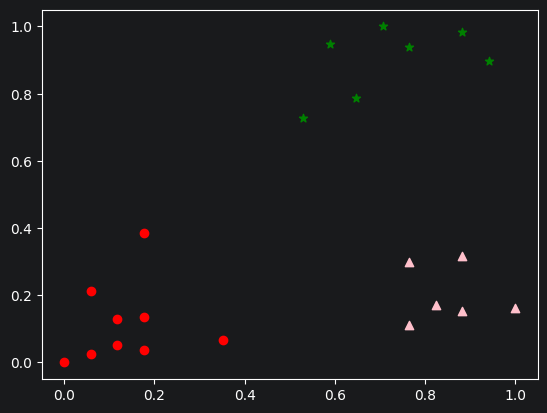

In [15]:
plt.scatter(df0["Age"], df0["Income($)"], marker='o', color='red')
plt.scatter(df1["Age"], df1["Income($)"], marker='*', color='green')
plt.scatter(df2["Age"], df2["Income($)"], marker='^', color='pink')

In [16]:
km.cluster_centers_

array([[0.1372549 , 0.11633428],
       [0.72268908, 0.8974359 ],
       [0.85294118, 0.2022792 ]])

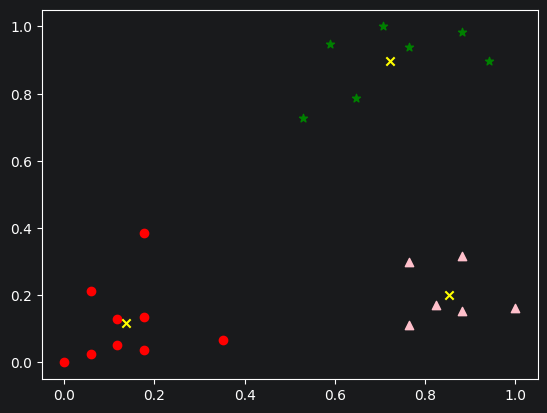

In [18]:
plt.scatter(df0["Age"], df0["Income($)"], marker='o', color='red')
plt.scatter(df1["Age"], df1["Income($)"], marker='*', color='green')
plt.scatter(df2["Age"], df2["Income($)"], marker='^', color='pink')
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], marker='x', color='yellow')

In [21]:
# Elbow plot
k_rng = range(1, 10)
sse = []
for k in k_rng:
    km = KMeans(n_clusters=k)
    y_predicted = km.fit_predict(df[["Age", "Income($)"]])
    sse.append(km.inertia_)

In [22]:
sse

[5.434011511988179,
 2.3456144914725936,
 0.4750783498553096,
 0.3625079900797329,
 0.28607171066894405,
 0.26766565553311783,
 0.22423356742627443,
 0.15205897076959982,
 0.11612804668175383]

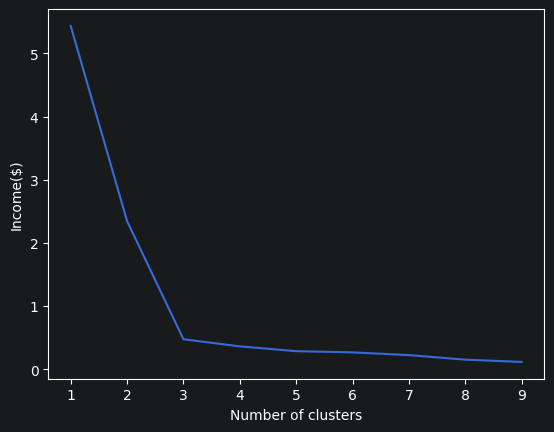

In [24]:
plt.xlabel("Number of clusters")
plt.ylabel("Income($)")
plt.plot(k_rng, sse)